In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import numba
from ipywidgets import interact, interactive, IntSlider, ToggleButtons
from scipy.optimize import curve_fit
import pandas as pd

In [ ]:
def expo1(x,a,b,c):
    return  np.abs(a)/(1+np.exp(np.abs(b)*(c-x)))

In [ ]:
def step(j, rad, Fp, Fi, c_max,c_p0,c_i0, c_p, c_m1, c_i, D_i, D_p, h, k):
    # Update concentrations at the boundary (index 0)
    c_p0[0] = c_p0[1] + Fp * k/D_p
    c_i0[0] = c_i0[1] + Fi * k/D_i

    # Iterate over the internal grid points
    for i in range(1, rad - 1):
        # Update concentrations based on the reaction-diffusion equations
        c_i[i] = c_i0[i] + h * D_i/np.square(k) * ((1 + 1 / (2 * i)) * c_i0[i + 1] - 2 * c_i0[i] + (1 - 1 / (2 * i)) * c_i0[i - 1])
        c_p[i] = c_p0[i] + h * D_p/np.square(k) * ((1 + 1 / (2 * i)) * c_p0[i + 1] - 2 * c_p0[i] + (1 - 1 / (2 * i)) * c_p0[i - 1])

        # Preserve the previous concentration value in c_m1
        c_m1[i, j + 1] = c_m1[i, j]

        # Check if c_m1 is below the maximum concentration threshold
        if c_m1[i, j] <= c_max:
            # Check if concentration of c_p is higher than c_i
            if c_p[i] > c_i[i]:
                # Update c_m1 and decrease c_p
                c_m1[i, j + 1] += (c_p[i] - c_i[i]) * h
                c_p[i] -= (c_p[i] - c_i[i]) * h

    # Set the concentration values at the outer boundary (index rad-1) to their previous values
    c_i[rad - 1] = c_i[rad - 2]
    c_p[rad - 1] = c_p[rad - 2]
    i = rad - 1

    # Preserve the previous concentration value in c_m1 for the outer boundary
    c_m1[i, j + 1] = c_m1[i, j]

    # Check if c_m1 for the outer boundary is below the maximum concentration threshold
    if c_m1[i, j] <= c_max:
        # Check if concentration of c_p is higher than c_i for the outer boundary
        if c_p[i] > c_i[i]:
            # Update c_m1 and decrease c_p for the outer boundary
            c_m1[i, j + 1] += (c_p[i] - c_i[i]) * h
            c_p[i] -= (c_p[i] - c_i[i]) * h



numb_step= numba.jit(step,nopython=True)

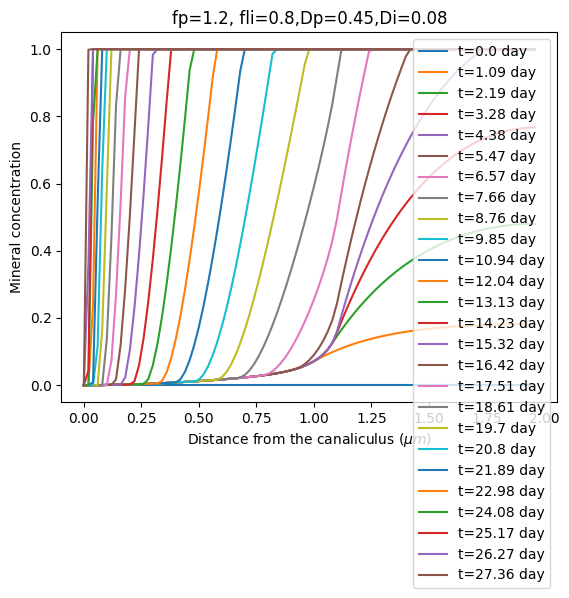

In [ ]:

D_p=0.45


flp=1.2

fl1=0.8

timesteps=10000001
D_i=0.08

k=0.01
h=0.45*np.square(k)/D_p
#all the positions r are scaled by rad
rad=int(1/k)

c_i=np.zeros([rad])
c_p=np.zeros([rad])
c_i0=np.zeros([rad])
c_p0=np.zeros([rad])
c_m1=np.zeros([rad,timesteps])
somma=np.zeros([timesteps])
endtime=0



c_max=1.
eps=0.001

radius=[]
zero=0


Fi=fl1/(2*np.pi*k)
Fp=flp/(2*np.pi*k)
for j in range(0,timesteps-1):
  c_i0=c_i.copy()
  c_p0=c_p.copy()
  numb_step(j,rad,Fp,Fi,c_max,c_p0,c_i0,c_p,c_m1,c_i,D_i,D_p,h,k)
  tot=0
  for i in range(0,rad):
    tot+=(k**2)*(-i**2+(i+1)**2)*np.pi*c_m1[i,j]
  somma[j]=tot
  if(abs(tot-(np.pi*((rad)*k)**2)/2.)<=0.0001): zero=j*h/2.
  if((endtime==0) and all(c_m1[1:-1,j]> c_max-eps)) :
    endtime=j*h/2.
    break
colors = plt.cm.rainbow(np.linspace(0,1,20))
for l in range(0,j+1,int((j)/25)):
  plt.plot(2*np.arange(rad-1)/rad,c_m1[:-1,l],label="t={} day".format(round(l*h/2.,2)))

  plt.xlabel("Distance from the canaliculus ($\mu m$)")
plt.title("fp={}, fli={},Dp={},Di={}".format(round(flp,3),round(fl1,3),D_p,D_i))
plt.ylabel("Mineral concentration")
plt.legend()


Text(0, 0.5, 'Average mineralization $\\overline{C}_m(r)$')

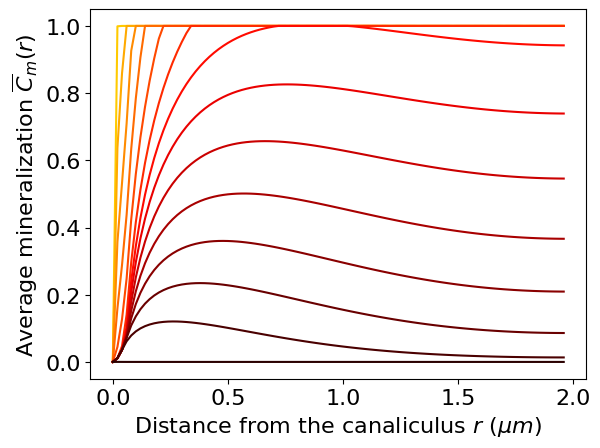

In [ ]:
N=13
colors = plt.cm.hot(np.linspace(0,1,N+9))
plt.rcParams.update({'font.size': 16})
for n_c,l in enumerate(range(j-1,0,-int((j)/N))):
  plt.plot(2*np.arange(rad-1)/rad,c_m1[:-1,l],c=colors[-8-n_c],label="t={} day".format(round(l*h/2.,2)))

  # plt.xlabel("Distance from the canaliculus ($\mu m$)")
  # plt.title("fp={}, fli={},Dp={},Di={}".format(round(flp,3),round(fl1,3),D_p,D_i))
  # plt.ylabel("Mineral concentration")
#plt.title("fp={}, fli={},Dp={},Di={}".format(round(flp,3),round(fl1,3),D_p,D_i))
#plt.legend()
plt.xlabel("Distance from the canaliculus $r$ $(µm)$")
plt.ylabel(r"Average mineralization $\overline{C}_m(r)$")

Text(0, 0.5, 'Total mineral')

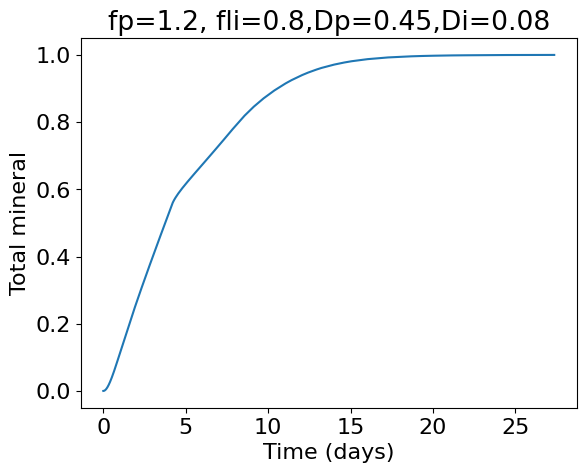

In [ ]:
plt.plot(np.linspace(0,j*h/2,j),somma[:j]/np.pi)
plt.title("fp={}, fli={},Dp={},Di={}".format(round(flp,3),round(fl1,3),D_p,D_i))
plt.xlabel("Time (days)")
plt.ylabel("Total mineral")

In [ ]:
df=pd.DataFrame()

NameError: name 'df' is not defined

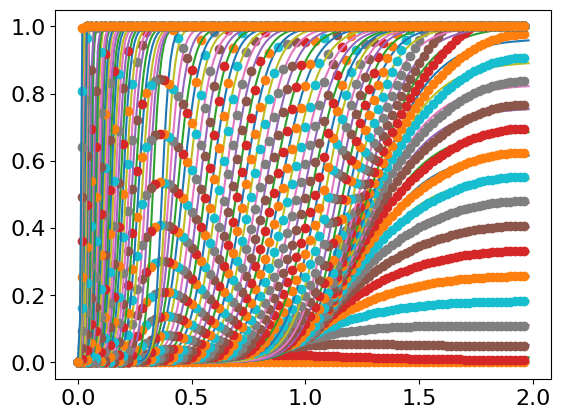

In [ ]:

d=int((j-1)/100)
cross4=np.zeros((101,6))
pw0=np.array([0.4,100,1]).astype(float)
err=np.zeros((int(len(c_m1[0,:j])/d+1),3,3))
param_bounds=([0,0,0],[1,900,2])
sigma=np.ones(rad-1)
for i in range(int(1*rad/5)):
  sigma[i]=10
for N in range(0,int(j-1),int((j-1)/100)):
    pw,cov = curve_fit(expo1,(2.*np.arange(rad-1)/rad), c_m1[:-1,N] ,pw0,maxfev = 200000,bounds=param_bounds,sigma=sigma,absolute_sigma=False)

    cross4[int(N/d),0]=pw[0]
    cross4[int(N/d),1]=pw[1]
    cross4[int(N/d),2]=pw[2]
  #  cross4[int(N/d),3]=pw[3]
    cross4[int(N/d) ,4]=N*h/2.
    residuals = c_m1[:-1,N]- expo1((2*np.arange(rad-1)/rad), *pw)
    cross4[int(N/d) ,5] = np.sum(residuals**2)
    err[int(N/d)]=cov
    plt.plot(2*np.linspace(0,rad-1,2*rad)/rad,expo1((2*np.linspace(0,rad-1,2*rad)/rad),*pw) )
    plt.plot(2*np.arange(rad-1)/rad,c_m1[:-1,N],"o",label="t={}".format(N*h))
#plt.legend()
df1=pd.DataFrame({"D_i":D_i,"D_p":D_p,"F_i":fl1,"F_p":flp,"a":cross4[:,0],"b":cross4[:,1],"endtime":endtime,"zero":zero,"c":cross4[:,2],"N":cross4[:,4],"min":somma[:j:d]/np.pi})
df=pd.concat([df,df1])

In [ ]:
somma=np.zeros(len(cross4))
for i,x in enumerate(cross4):
    step_size=0.001
    c=x[2]
    b=x[1]
    a=x[0]
    for r in np.arange(0,2,step_size):
      somma[i]+=r*step_size*a/(1+np.exp(-b*(r-c)))
    somma[i]=somma[i]*2*np.pi/(2*2*np.pi)

(0.0, 60.0)

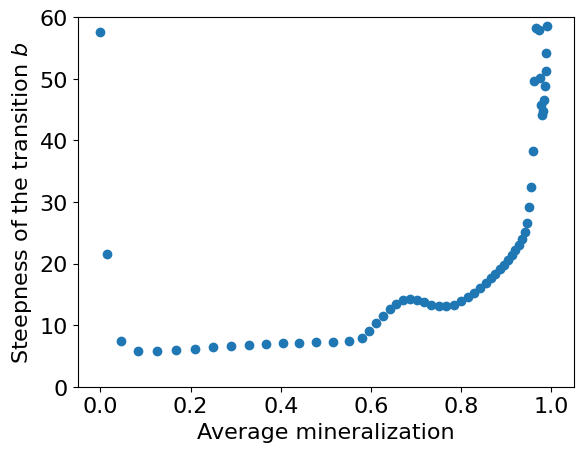

In [ ]:
plt.scatter(somma,cross4[:,1])
plt.ylabel("Steepness of the transition $b$")
plt.xlabel("Average mineralization")
plt.ylim(0,60)

In [ ]:


plt.rc('font', size=16)

for i,sets in enumerate(reversed(df[["D_i",	"D_p","F_i","F_p" ]	].drop_duplicates().to_dict("records"))):

  if i==8:
    color=[217./255.,95./255.,2./255.,1]
  else:
    color=[117./255,112./255,179./255,0.6]

  #colore=(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].endtime.iloc[0])/np.max(df.N+50)
  x=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].N
  y=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)]["min"]ab.research.google.com/
  plt.plot(x[x>0.05],y[x>0.05],color=color)
  plt.xlabel("Time (days)")
  plt.ylabel("Average mineralization")



In [ ]:
df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)]["min"]

0      0.000000
1      0.052755
2      0.133942
3      0.202641
4      0.259572
         ...   
96     0.999641
97     0.999682
98     0.999741
99     0.999815
100    0.999906
Name: min, Length: 101, dtype: float64

In [ ]:

D_i=0.04
D_p=0.45
fl1=0.8
flp=1.2
param_names=["D_i","D_p","F_i","F_p"]
param_set=[D_i,D_p,fl1,flp]
list_sets.append(dict(zip(param_names, param_set)))


In [ ]:

for sets in list_sets:
  if i==1:
    color=[217./255.,95./255.,2./255.,1]
  else:
    color=[117./255,112./255,179./255,0.6]
  colore=(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].endtime.iloc[0])/np.max(df.N+50)
  x1=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].N
  x=x1.copy()
  x/=np.max(x1)
  y_index=np.argmin(np.abs(x1-(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].zero.iloc[0])))
  y=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].a
  plt.plot(3*(x[2::]-(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].zero.iloc[0])/np.max(x1)),y[2::],marker=".",label=sets,color=color)
  #plt.scatter((df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].zero.iloc[0])/np.max(x1),y.iloc[y_index],color="b")
#plt.legend(bbox_to_anchor=[1,1])
plt.xlabel("Distance from the macroscopic mineralization front ($µm$)",fontsize=12)
plt.ylabel("Average mineralization in the macroscopic \n mineralization front $a$", fontsize=12)


In [ ]:

for sets in list_sets:
  colore=(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].endtime.iloc[0])/np.max(df.N+50)
  x1=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].N
  x=x1.copy()
  x=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].a
  y_index=np.argmin(np.abs(x1-(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].zero.iloc[0])))
  y=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].c
  plt.plot(x[2::],y[2::],marker=".",label=sets,color=plt.cm.hot(colore))
  #plt.scatter((df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].zero.iloc[0])/np.max(x1),y.iloc[y_index],color="b")
#plt.legend(bbox_to_anchor=[1,1])
plt.xlabel("Mineralization level in the surrounding $a$",fontsize=12)
plt.ylabel("Distance from the microscopic \n mineralization front $c$ ($µm$)", fontsize=12)
plt.ylim(0,1.6)

In [ ]:
df=df.drop_duplicates()
df

,Unnamed: 0,D_i,D_p,F_i,F_p,a,b,endtime,zero,c,N,min
0,0,0.08,0.45,0.8,1.2,0.000065,57.663070,27.36345,3.7542,1.987654,0.0000,0.000000
1,1,0.08,0.45,0.8,1.2,0.015300,21.539243,27.36345,3.7542,0.411793,0.2736,0.013057
2,2,0.08,0.45,0.8,1.2,0.052046,7.480789,27.36345,3.7542,0.706707,0.5472,0.044281
3,3,0.08,0.45,0.8,1.2,0.111394,5.856037,27.36345,3.7542,0.939927,0.8208,0.083731
4,4,0.08,0.45,0.8,1.2,0.182540,5.780924,27.36345,3.7542,1.064863,1.0944,0.125765
...,...,...,...,...,...,...,...,...,...,...,...,...
904,96,0.06,0.45,0.8,1.2,1.000000,739.501551,35.05200,3.4017,0.021549,33.6480,0.999683
905,97,0.06,0.45,0.8,1.2,1.000000,719.020047,35.05200,3.4017,0.020669,33.9985,0.999725
906,98,0.06,0.45,0.8,1.2,1.000000,602.683469,35.05200,3.4017,0.019633,34.3490,0.999777
907,99,0.06,0.45,0.8,1.2,1.000000,595.540170,35.05200,3.4017,0.018062,34.6995,0.999838


In [ ]:
plt.rcParams.update({'font.size': 16})
for i,sets in enumerate(reversed(list_sets)):

  if i==10:
    color=[217./255.,95./255.,2./255.,1]
  else:
    color=[117./255,112./255,179./255,0.6]

  colore=(df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].endtime.iloc[0])/np.max(df.N+50)
  x=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].a
  y=df.loc[ np.all(df[list(sets)] == pd.Series(sets), axis=1)].c
  plt.plot(x[((y<1.6) & (y>0.1))],y[((y<1.6) & (y>0.1))],color=color)
  plt.xlabel("a")
  plt.ylabel("c ($\mu m$)")


NameError: name 'list_sets' is not defined

In [ ]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/param_plots/fit_with_sums.csv")

In [ ]:
df[df["D_p"]==sets["D_p"]][df["F_p"]==sets["F_p"]].N

0             0.0
1             0.0
2             0.0
3             0.0
4             0.0
          ...    
1004          0.0
1005          0.0
1006          0.0
1007          0.0
1008    1008500.0
Name: N, Length: 3541, dtype: float64

129.04500000000002

<ipython-input-30-a9f983a77cdc>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Nbinned'] = pd.cut(df.N, bins,labels=labels)


Text(0.5, 0, 'Concentration at the plateau $a$')

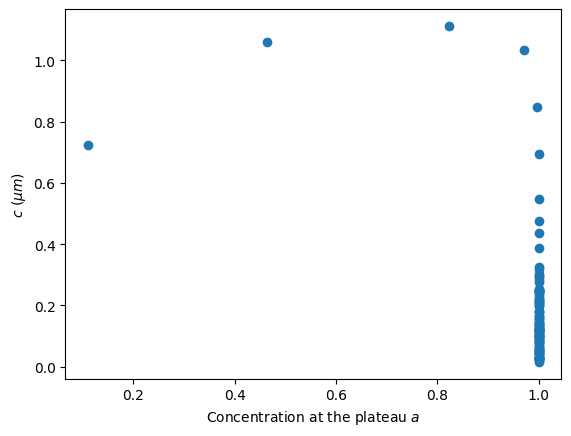

In [ ]:
n_bins=100
bins=np.linspace(0,np.max(df.N),n_bins)
labels=np.fromiter(((bins[x]+bins[x+1])/2 for x in range(n_bins)),dtype=float, count=(n_bins-1))
df['Nbinned'] = pd.cut(df.N, bins,labels=labels)
plt.scatter(df.groupby("Nbinned").mean().a,df.groupby("Nbinned").mean().c)
plt.ylabel("$c$ ($µm$)")
plt.xlabel("Concentration at the plateau $a$")

<ipython-input-25-0d9fca9622da>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["scaled"]=df.N/df.endtime
<ipython-input-25-0d9fca9622da>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Nbinned'] = pd.cut(df.N/df.endtime, bins,labels=labels)


Text(0.5, 0, 'Concentration at the plateau $a$')

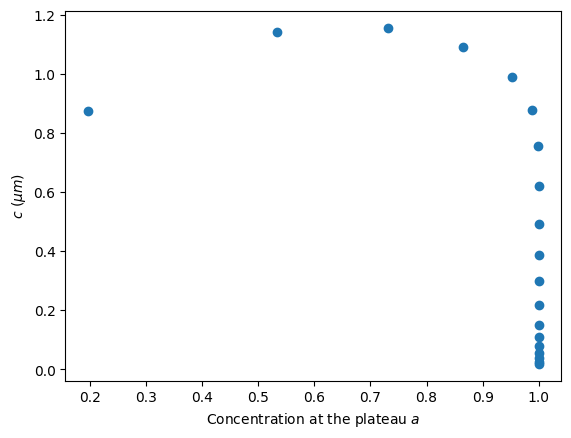

In [ ]:
df["scaled"]=df.N/df.endtime
n_bins=20
bins=np.linspace(0,1,n_bins)
labels=np.fromiter(((bins[x]+bins[x+1])/2 for x in range(n_bins)),dtype=float, count=(n_bins-1))
df['Nbinned'] = pd.cut(df.N/df.endtime, bins,labels=labels)
plt.scatter(df.groupby("Nbinned").mean().a,df.groupby("Nbinned").mean().c)
plt.ylabel("$c$ ($µm$)")
plt.xlabel("Concentration at the plateau $a$")

In [ ]:
df=df.dropna()

In [ ]:
list_sets

[{'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.2},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 1.0, 'F_p': 1.2},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.6, 'F_p': 1.2},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.0},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.4},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.6, 'F_p': 1.5},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 1.0, 'F_p': 1.5},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 1.0, 'F_p': 1.1},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.6, 'F_p': 1.1},
 {'D_i': 0.12, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.2},
 {'D_i': 0.04, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.2}]

In [ ]:
df

,Unnamed: 0,D_i,D_p,F_i,F_p,a,b,endtime,zero,c,N
0,0,0.08,0.45,0.8,1.0,0.000065,57.663070,55.1603,6.83525,1.987654,0.00000
1,1,0.08,0.45,0.8,1.0,0.043118,6.387237,55.1603,6.83525,0.816629,0.55160
2,2,0.08,0.45,0.8,1.0,0.152494,5.716415,55.1603,6.83525,1.183333,1.10320
3,3,0.08,0.45,0.8,1.0,0.268270,6.336856,55.1603,6.83525,1.288953,1.65480
4,4,0.08,0.45,0.8,1.0,0.374934,6.801199,55.1603,6.83525,1.339348,2.20640
...,...,...,...,...,...,...,...,...,...,...,...
1207,96,0.04,0.45,0.8,1.2,1.000000,796.084427,50.4291,2.85870,0.023217,48.40800
1208,97,0.04,0.45,0.8,1.2,1.000000,790.126247,50.4291,2.85870,0.021732,48.91225
1209,98,0.04,0.45,0.8,1.2,1.000000,795.407227,50.4291,2.85870,0.020507,49.41650
1210,99,0.04,0.45,0.8,1.2,1.000000,613.149332,50.4291,2.85870,0.018882,49.92075


In [ ]:
#df.to_csv("/content/drive/MyDrive/Colab Notebooks/param_plots/fit_with_sums.csv")

In [ ]:
# import pickle
# output = open("/content/drive/MyDrive/Colab Notebooks/param_plots/list_sets.pkl", 'wb')
# pickle.dump(list_sets, output)


In [ ]:
import pickle
with open("/content/drive/MyDrive/Colab Notebooks/param_plots/list_sets.pkl", 'rb') as f:
    list_sets= pickle.load(f)

In [ ]:
x

[{'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.2},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 1.0, 'F_p': 1.2},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.6, 'F_p': 1.2},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.0},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.4},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.6, 'F_p': 1.5},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 1.0, 'F_p': 1.5},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 1.0, 'F_p': 1.1},
 {'D_i': 0.08, 'D_p': 0.45, 'F_i': 0.6, 'F_p': 1.1},
 {'D_i': 0.12, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.2},
 {'D_i': 0.04, 'D_p': 0.45, 'F_i': 0.8, 'F_p': 1.2}]

In [ ]:
#plt.plot(cross0[:,3],abs(cross0[:,0 ]), marker='o')
par=2
plt.rcParams.update({'font.size': 18})
#plt.plot(np.linspace(0,1,len(cross0[:,0])),abs(cross0[:,par]),color=[27./255.,158./255.,119./255.],label="0")
# plt.plot(np.linspace(0,1,len(cross1[:,0])),abs(cross1[:,par]),color=[217./255.,95./255.,2./255.],label="1")
# plt.plot(np.linspace(0,1,len(cross2[:,0])),abs(cross2[:,par]),label="2")
# plt.plot(np.linspace(0,1,len(cross3[:,0])),abs(cross3[:,par]),label="3")
plt.plot(somma[:j:int(j/100)]/3.14,abs(cross4[:,0]),label="5")
#plt.plot(np.linspace(0,1,len(cross4[:,0])),abs(cross4[:,0]),label="5")
# plt.plot(np.linspace(0,1,len(cross5[:,0])),abs(cross5[:,par]),label="5")
# plt.plot(np.linspace(0,1,len(cross6[:,0])),abs(cross6[:,par]),label="1.5")
# plt.plot(np.linspace(0,1,len(cross7[:,0])),abs(cross7[:,par]),label="7")
# plt.plot(np.linspace(0,1,len(cross8[:,0])),abs(cross8[:,par]),label="8")
# plt.plot(np.linspace(0,1,len(cross9[:,0])),abs(cross9[:,par]),label="9")
# plt.plot(np.linspace(0,1,len(cross10[:,0])),abs(cross10[:,par]),label="10")
# plt.plot(np.linspace(0,1,len(cross11[:,0])),abs(cross11[:,par]),label="11")

#plt.title("parameter $a+d$ flp={},fli={},D_p={}".format(flp,fl1,D_p))
plt.xlabel("Normalized days")
plt.ylabel("$c$ ")
plt.legend()

NameError: name 'plt' is not defined

In [ ]:
df

,D_i,D_p,F_i,F_p,a,b,c,N
0,0.32,0.45,1.5,2,0.000065,5.766307e+01,1.987654,0.0
1,0.32,0.45,1.5,2,0.001057,3.955414e-12,1.999146,1000.0
2,0.32,0.45,1.5,2,0.004045,1.271566e-14,1.999611,2000.0
3,0.32,0.45,1.5,2,0.008300,1.431879e-11,1.999999,3000.0
4,0.32,0.45,1.5,2,0.013571,3.159125e-16,0.000002,4000.0
...,...,...,...,...,...,...,...,...
997,0.32,0.45,1.9,2,1.000000,6.440668e+02,0.016044,997000.0
998,0.32,0.45,1.9,2,1.000000,6.753995e+02,0.015791,998000.0
999,0.32,0.45,1.9,2,1.000000,6.563958e+02,0.015051,999000.0
1000,0.32,0.45,1.9,2,1.000000,6.840842e+02,0.014277,1000000.0


<ipython-input-115-e45cc7f043cf>:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plt.plot(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.5].N/len(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.5].N),df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.5].a)
<ipython-input-115-e45cc7f043cf>:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plt.plot(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.9].N/len(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.9].N),df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.9].a)


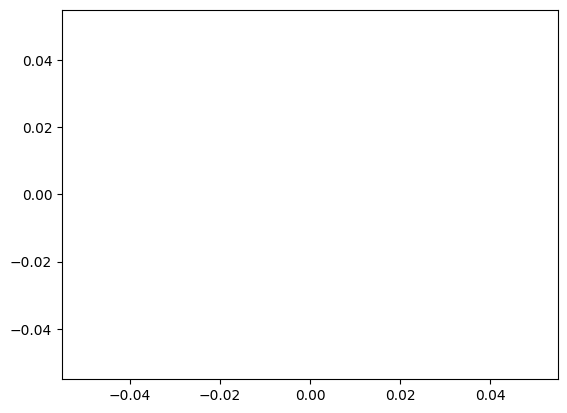

In [ ]:
plt.plot(df[ df["D_p"]==0.45][df["D_i"]==0.0+34][df["F_p"]==2][df["F_i"]==1.5].N/len(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.5].N),df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.5].a)
plt.plot(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.9].N/len(df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.9].N),df[ df["D_p"]==0.45][df["D_i"]==0.04][df["F_p"]==2][df["F_i"]==1.9].a)

In [ ]:
df[ df["D_p"]==0.45][df["D_i"]==0.04]

,D_i,D_p,F_i,F_p,a,b,endtime,zero,c,N
0,0.04,0.45,0.8,1.2,0.000065,57.663070,50.4291,2.8587,1.987654,0.00000
1,0.04,0.45,0.8,1.2,0.053725,12.264625,50.4291,2.8587,0.511133,0.50425
2,0.04,0.45,0.8,1.2,0.182697,6.172864,50.4291,2.8587,0.874714,1.00850
3,0.04,0.45,0.8,1.2,0.369714,5.450431,50.4291,2.8587,1.094473,1.51275
4,0.04,0.45,0.8,1.2,0.576863,5.538687,50.4291,2.8587,1.212096,2.01700
...,...,...,...,...,...,...,...,...,...,...
96,0.04,0.45,0.8,1.2,1.000000,796.084427,50.4291,2.8587,0.023217,48.40800
97,0.04,0.45,0.8,1.2,1.000000,790.126247,50.4291,2.8587,0.021732,48.91225
98,0.04,0.45,0.8,1.2,1.000000,795.407227,50.4291,2.8587,0.020507,49.41650
99,0.04,0.45,0.8,1.2,1.000000,613.149332,50.4291,2.8587,0.018882,49.92075


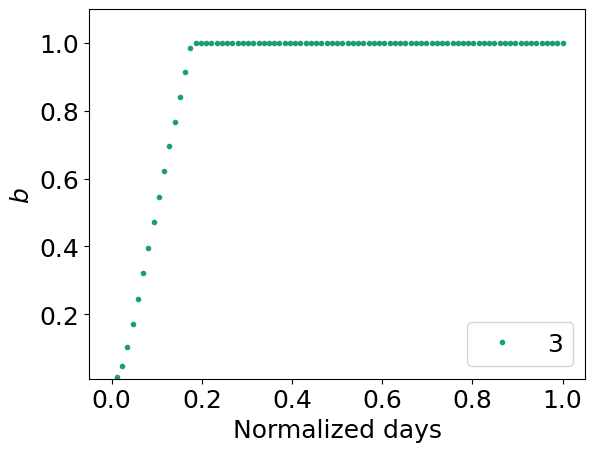

In [ ]:
#plt.plot(cross0[:,3],abs(cross0[:,0 ]), marker='o')
plt.rcParams.update({'font.size': 18})
plt.plot(np.linspace(0,1,len(cross0[:,0])),abs(cross0[:,0]),".",color=[27./255.,158./255.,119./255.],label="3")
# plt.plot(np.linspace(0,1,len(cross1[:,0])),abs(cross1[:,1]),".",color=[217./255.,95./255.,2./255.],label="2")
# plt.plot(np.linspace(0,1,len(cross2[:,0])),abs(cross2[:,1]),".",color=[117./255,112./255,179./255],label="3")
plt.ylim(.010,1.1)
#plt.title("parameter $a+d$ flp={},fli={},D_p={}".format(flp,fl1,D_p))
plt.xlabel("Normalized days")
plt.ylabel("$b$ ")
plt.legend()

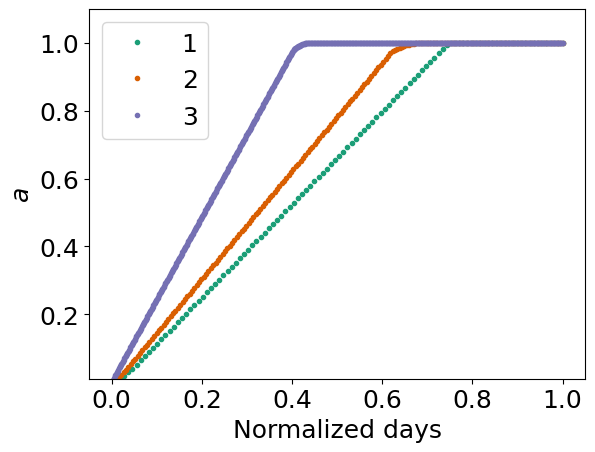

In [ ]:
#plt.plot(cross0[:,3],abs(cross0[:,0 ]), marker='o')
plt.rcParams.update({'font.size': 18})
plt.plot(np.linspace(0,1,len(cross0[:,0])),abs(cross0[:,0]),".",color=[27./255.,158./255.,119./255.],label="1")
plt.plot(np.linspace(0,1,len(cross1[:,0])),abs(cross1[:,0]),".",color=[217./255.,95./255.,2./255.],label="2")
plt.plot(np.linspace(0,1,len(cross2[:,0])),abs(cross2[:,0]),".",color=[117./255,112./255,179./255],label="3")
plt.ylim(.010,1.1)
#plt.title("parameter $a+d$ flp={},fli={},D_p={}".format(flp,fl1,D_p))
plt.xlabel("Normalized days")
plt.ylabel("$a$ ")
plt.legend()

In [ ]:
for D_p in np.arange(0.1,1,0.02):
  out= pd.DataFrame(columns=['Fi','Fp',"Dp","Di","max"])

  fl1=0.5
  for D_i in np.arange(0.01,1,0.02 ):
    for m,flp in enumerate(np.arange(0.1,2,0.1)):
      if(flp<=fl1):     out=pd.concat([out, pd.DataFrame([[ round(fl1,2),  round(flp,2),D_p,D_i , -1]],columns=out.columns)],ignore_index=True)
      elif(D_p<=D_i):     out=pd.concat([out, pd.DataFrame([[ round(fl1,2),  round(flp,2),D_p,D_i , -1]],columns=out.columns)],ignore_index=True)
      else:
        timesteps=9020001

        k=0.5
        h=0.4*np.square(k)/D_p
        Fi=fl1/(2*np.pi*k)
        Fp=flp/(2*np.pi*k)
        rad=int(36/k)

        numb_step= numba.jit(step)

        c_i=np.zeros([rad,timesteps])
        c_p=np.zeros([rad,timesteps])
        c_m1=np.zeros([rad,timesteps])
        print(D_p*h/np.square(k))
        endtime=0

        c_max=1.
        eps=0.001

        radius=[]

        c_min=np.zeros([timesteps,2])

        for j in range(0,timesteps-1):
          numb_step(j,rad,Fp,Fi,c_max,c_p,c_m1,c_i,D_i,D_p,h,k)

          if (max(c_m1[:,j])>0.999999):

            out=pd.concat([out, pd.DataFrame([[ round(fl1,2),  round(flp,2), D_p,D_i, np.argmax(c_m1[:,j])/36*1.5*k]],columns=out.columns)],ignore_index=True)
            break

  plt.tight_layout()
  out["label"]=0
  out.loc[out["max"]<0,"label"]=-1
  out.loc[out["max"]>0.3,"label"]=1
  out.loc[out["max"]>1.2,"label"]=2
  out.to_csv("/content/drive/MyDrive/Colab Notebooks/d_n/fli_{}_dp_{}".format(fl1,round(D_p,3)))

0.4


TypeError: ignored

In [ ]:
import seaborn as sns
out_idx=out.reset_index(drop=True)
result=out_idx[['Fp','Di',"max"]]

result=result.drop_duplicates(subset=["Di","Fp"])
result=result.pivot(index="Di", columns="Fp", values="max")
plt.title("Position of the first mineralization D="+str(D_p))
ax=sns.heatmap(result.astype(float), cmap='viridis', fmt='.2f')
ax.invert_yaxis()
plt.show()

NameError: name 'out' is not defined

In [ ]:
import seaborn as sns
result=out[['Di','Fp',"label"]]
result=result.drop_duplicates(subset=["Di","Fp"])
result=result.pivot(index="Di", columns="Fp", values="label")
plt.title("Position of the first mineralization D="+str(dp))
ax=sns.heatmap(result, fmt="g", cmap='viridis',vmin=-1,vmax=2)

ax.invert_yaxis()

plt.show()

NameError: name 'out' is not defined

In [ ]:
def add_surf_D_i(D_i,fli,cmap="viridis"):
  path_to_csv="/content/drive/MyDrive/Colab Notebooks/d_n/fli_{}_di_{}".format(fli,D_i)
  ds=pd.read_csv(path_to_csv)
  my_map = ListedColormap([[1,1,1,0.1], [0.267004, 0.004874, 0.329415, 0.75], [0.993248, 0.906157, 0.143936,0.75],  [0.190631, 0.407061, 0.556089, 0.75    ]])


  # as plot_surface needs 2D arrays as input
  x = ds['Fp'].unique()
  z = ds['Dp'].unique()

  # we make a meshgrid from the x,y data
  X, Z = np.meshgrid(x, z)
  Y =np.ones_like(x)*D_i
  data_value = np.array([[ds.iloc[j+i*len(y)].label for j in range(len(y))] for i in range(len(x))])

  colors = cm.ScalarMappable(cmap = cmap).to_rgba(data_value)
  return  ax.plot_surface(X, Y, Z,facecolors=colors)

In [ ]:
def add_surf_1(D_i,flp,cmap="viridis"):
  path_to_csv="/content/drive/MyDrive/Colab Notebooks/d/flp_{}_di_{}".format(flp,D_i)
  ds=pd.read_csv(path_to_csv)
  my_map = ListedColormap([[1,1,1,0.1], [0.267004, 0.004874, 0.329415, 0.75], [0.993248, 0.906157, 0.143936,0.75],  [0.190631, 0.407061, 0.556089, 0.75    ]])


  # as plot_surface needs 2D arrays as input
  x = ds['Fi'].unique()
  y = ds['Dp'].unique()

  # we make a meshgrid from the x,y data
  X, Y = np.meshgrid(x, y)
  Z =np.ones_like(X)*D_i
  data_value = np.array([[ds.iloc[j+i*len(y)].label for j in range(len(y))] for i in range(len(x))])
  colors = cm.ScalarMappable(cmap = cmap).to_rgba(data_value)
  return  ax.plot_surface(X, Y, Z,facecolors=colors)

In [ ]:
def add_surf(D_p,fli,cmap="viridis"):
  path_to_csv="/content/drive/MyDrive/Colab Notebooks/d_n/fli_{}_dp_{}".format(fli,round(D_p,2))
  ds=pd.read_csv(path_to_csv)
  my_map = ListedColormap([[1,1,1,0.1], [0.267004, 0.004874, 0.329415, 0.75], [0.993248, 0.906157, 0.143936,0.75],  [0.190631, 0.407061, 0.556089, 0.75    ]])


  # as plot_surface needs 2D arrays as input
  x = ds['Fp'].unique()
  y = ds['Di'].unique()

  # we make a meshgrid from the x,y data
  X, Y = np.meshgrid(x, y)
  Z =np.ones_like(X)*D_p
  data_value = np.array([[ds.iloc[j+i*len(x)].label for j in range(len(x))] for i in range(len(y))])
  colors = cm.ScalarMappable(cmap = cmap).to_rgba(data_value)
  return  ax.plot_surface(X, Y, Z,facecolors=colors)


In [ ]:
def add_surf_fp(fp,fli,cmap="viridis"):
  path_to_csv="/content/drive/MyDrive/Colab Notebooks/d/fli_{}_flp_{}".format(fli,fp)
  ds=pd.read_csv(path_to_csv)
  my_map = ListedColormap([[1,1,1,0.1], [0.267004, 0.004874, 0.329415, 0.75], [0.993248, 0.906157, 0.143936,0.75],  [0.190631, 0.407061, 0.556089, 0.75    ]])
  # as plot_surface needs 2D arrays as input
  z = ds['Dp'].unique()
  y = ds['Di'].unique()
  # we make a meshgrid from the x,y data
  Y , Z = np.meshgrid(y, z)
  X = np.ones_like(y)*fp

  data_value = np.array([[ds.iloc[j+i*len(z)].label for i in range(len(y))] for j in range(len(z))])
  colors = cm.ScalarMappable(cmap = cmap).to_rgba(data_value)

  return  ax.plot_surface(X, Y, Z, facecolors=colors)

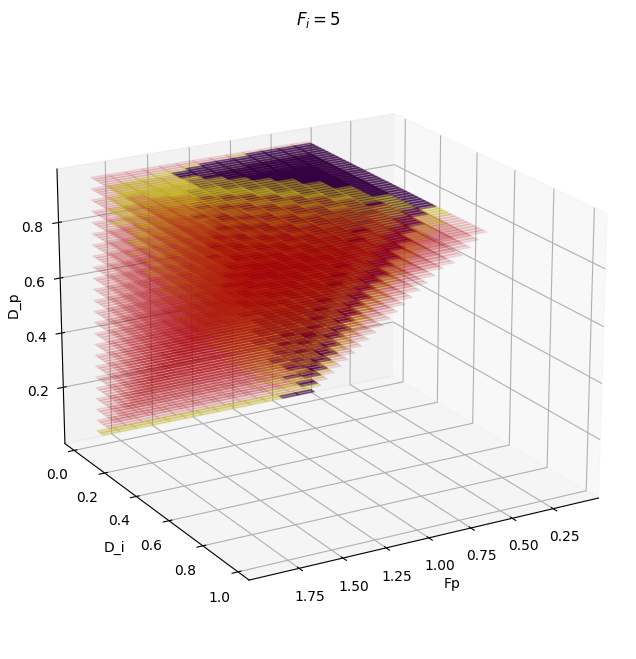

In [ ]:

from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.colors import ListedColormap

import plotly.express as px

my_map = ListedColormap([[1,1,1,0.],  [0.90631, 0.007061, 0.056089, 0.1    ],[0.993248, 0.906157, 0.143936,0.3] ,[0.267004, 0.004874, 0.329415, 0.5] ])
fig = plt.figure(figsize=(8,8))
ax=fig.add_subplot(projection="3d")
#add_surf(D=12.5,cmap=my_map)
#add_surf(D_p=10,fli=8,cmap=my_map)
# add_surf(D_p=7.5,fli=8,cmap=my_map)
#add_surf(D_p=5,fli=8,cmap=my_map)
# add_surf(D_p=2.5,fli=8,cmap=my_map)
#add_surf(D_p=8,fli=5,cmap=my_map)
#add_surf_D_i(D_i=1.0,fli=8,cmap=my_map)
#add_surf_D_i(D_i=4,fli=5,cmap=my_map)
# add_surf_fp(fp=12,fli=5,cmap=my_map)
# add_surf_fp(8,5,cmap=my_map)
# add_surf_fp(10,5,cmap=my_map)
# add_surf_fp(6,5,cmap=my_map)
for D_p in np.arange(0.01,1,0.04):
  add_surf(D_p=D_p,fli=0.5,cmap=my_map)

# add_surf_D_i(D_i=5,fli=8,cmap=my_map)
# add_surf_D_i(D_i=0.5,fli=8,cmap=my_map)
ax.set_xlabel("Fp")
ax.set_ylabel("D_i")
plt.title(r"$F_i=${}".format(5))
ax.set_zlabel("D_p", rotation=90)
ax.view_init(elev=20, azim=60)
ax.zaxis.labelpad=0.1
plt.show()

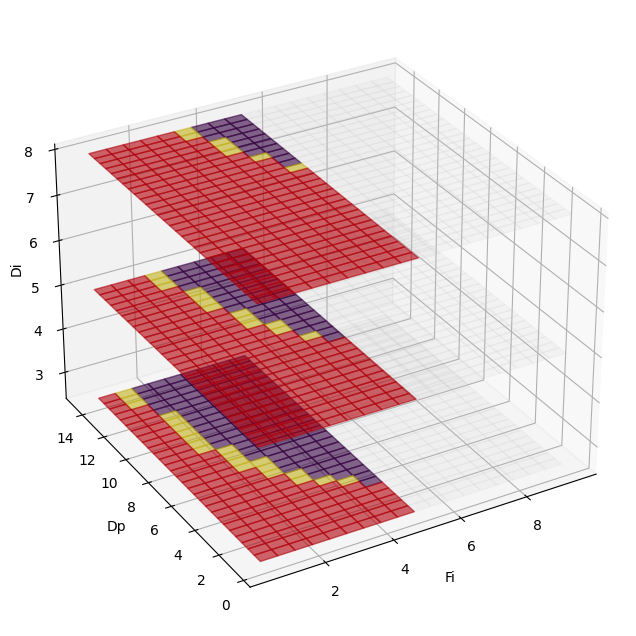

In [ ]:
my_map = ListedColormap([[1,1,1,0.1],  [0.90631, 0.007061, 0.056089, 0.6    ],[0.993248, 0.906157, 0.143936,0.6] ,[0.267004, 0.004874, 0.329415, 0.6] ])
fig = plt.figure(figsize=(8,8))
ax=fig.add_subplot(projection="3d")
add_surf_1(D_i=2.5,flp=5,cmap=my_map)
add_surf_1(D_i=5,flp=5,cmap=my_map)
add_surf_1(D_i=8,flp=5,cmap=my_map)
plt.xlabel("Fi")
plt.ylabel("Dp")
ax.view_init(elev=30, azim=-120)
ax.zaxis.labelpad=-1.5
ax.set_zlabel("Di", rotation=90)
plt.show()

In [ ]:
path_to_csv="/content/drive/MyDrive/Colab Notebooks/d/flp_{}_di_{}".format(flp,D_i)
ds=pd.read_csv(path_to_csv)
my_map = ListedColormap([[1,1,1,0.1], [0.267004, 0.004874, 0.329415, 0.75], [0.993248, 0.906157, 0.143936,0.75],  [0.190631, 0.407061, 0.556089, 0.75    ]])


# as plot_surface needs 2D arrays as input
x = ds['Fi'].unique()
y = ds['Dp'].unique()

x

NameError: name 'flp' is not defined

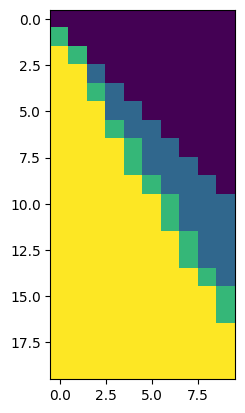

In [ ]:
import seaborn as sns
path_to_csv="/content/drive/MyDrive/Colab Notebooks/d/fli_5_flp_8"
ds=pd.read_csv(path_to_csv)
my_map = ListedColormap([[1,1,1,0.1], [0.267004, 0.004874, 0.329415, 0.75], [0.993248, 0.906157, 0.143936,0.75],  [0.190631, 0.407061, 0.556089, 0.75    ]])
result=ds[['Di','Dp',"label"]]
result=result.drop_duplicates(subset=["Di","Dp"])
result=result.pivot(index="Di", columns="Dp", values="label")

z = ds['Dp'].unique()
y = ds['Di'].unique()
# we make a meshgrid from the x,y data
Y , Z = np.meshgrid(y, z)
X = np.ones_like(y)*1
data_value = np.array([[ds.iloc[j+i*len(z)].label for i in range(len(y))] for j in range(len(z))])


#ax=sns.heatmap(result, fmt="g", cmap='viridis',vmin=-1,vmax=2)
ax.invert_yaxis()

colors = cm.ScalarMappable(cmap = my_map).to_rgba(data_value)
plt.imshow(data_value)

In [ ]:
ds

,Unnamed: 0,Fi,Fp,Dp,Di,max,label
0,0,5,8,0.5,0.5,-1.000000,-1
1,1,5,8,1.5,0.5,1.166667,1
2,2,5,8,2.5,0.5,1.270833,2
3,3,5,8,3.5,0.5,1.312500,2
4,4,5,8,4.5,0.5,1.333333,2
...,...,...,...,...,...,...,...
195,195,5,8,15.5,9.5,0.791667,1
196,196,5,8,16.5,9.5,1.145833,1
197,197,5,8,17.5,9.5,1.250000,2
198,198,5,8,18.5,9.5,1.312500,2


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Colab Notebooks/d_n/fli_8_dp_7.5'

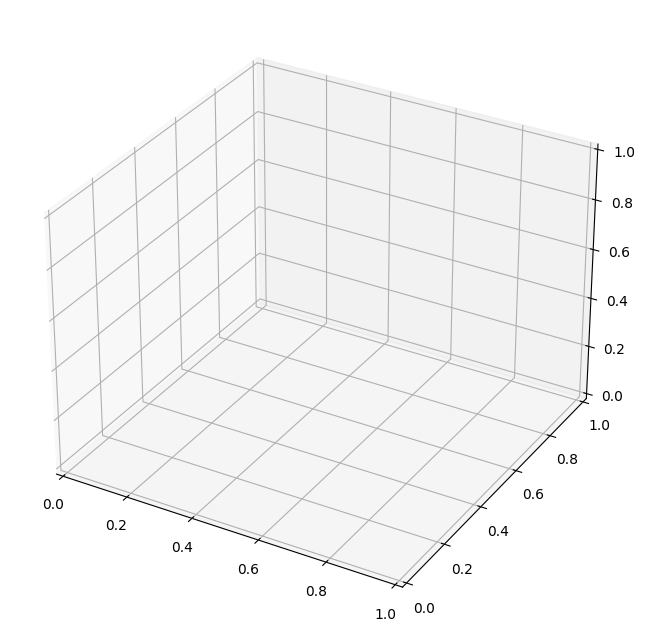

In [ ]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.colors import ListedColormap

my_map = ListedColormap([[1,1,1,0.1],  [0.90631, 0.007061, 0.056089, 0.55    ],[0.993248, 0.906157, 0.143936,0.55] ,[0.267004, 0.004874, 0.329415, 0.55] ])
fig = plt.figure(figsize=(8,8))
ax=fig.add_subplot(projection="3d")
#add_surf(D=12.5,cmap=my_map)
#add_surf(D_p=10,fli=8,cmap=my_map)
add_surf(D_p=7.5,fli=8,cmap=my_map)
add_surf(D_p=5,fli=8,cmap=my_map)
add_surf(D_p=2.5,fli=8,cmap=my_map)
ax.set_xlabel("Fp")
ax.set_ylabel("D_i")
ax.set_zlabel("D_p", rotation=90)
ax.view_init(elev=30, azim=-120)
ax.zaxis.labelpad=-1.5
plt.show()